# 笔记 4：What Drives Base-Model Choice（Section 5）的写作底稿（第二版）

这份笔记把 **Section 5** 需要的结果集中在一处：每个结论用哪张表、哪个数字支撑，怎么解释，放正文还是附录。

**第二版的变化（2026-11-26）：** 探索性实验已全量完成（`scripts/v2_explore.py`），据此重新确定了叙述逻辑。
- **新增 5.3 "流行由什么构成"：** 把流行拆开后，累积采纳（经典的马太效应）只占约四分之一。这是对"solid but boring"的主要回应。
- **5.4 增加集约边际：** 只看已被使用过的候选，流行仍占 94%。
- **增长消融、平台反事实、留存**移交给 Section 6 和 Section 7（§7）。
- **先行者分析删除**（§9）。
- §0.3 是全部结果的分配清单。

**口径：**
- **主规格 P5：** 首次采纳，(d+1) PPS 候选集，五组特征（流行、通用质量、需求匹配、自供给、习惯），按选择加权。
- **区间：** 50 次按作者的乘数 bootstrap。流行组内拆分用 20 次。

**代码：**
- 单元格已经运行过。重跑：`sbatch slurm/nb.sbatch notebooks/note4_results.ipynb`，约需 40 GB 内存；§4 读取 3,500 万行候选。
- 所有数字直接读自 `results/tables/v2/` 和 `processed/choices/v2_pps/v2_samples/`。

**目录**
0. 写作思路：主线、小节结构、全部结果的分配清单
1. 5.1 主结果：流行解释了几乎所有能解释的部分
2. 5.2 流行是不是隐藏的质量？
3. 5.3 流行由什么构成：大部分不是累积优势（新）
4. 5.4 适合：被看重、是开发者特有的，但很少起决定作用
5. 5.5 谁在跟随流行？
6. 5.6 稳健性（正文部分：样本选择）
7. 移交给 Section 6 和 Section 7 的结果：增长消融、平台反事实、留存
8. 附录 D：稳健性检验
9. 删除的结果：先行者
10. 表、图、宏与草稿修改
11. 审稿人可能的追问

## 0. 写作思路

### 0.1 主线（一段话）
开发者选基座模型时：
- **流行解释了几乎所有能解释的部分**（92%，5.1）。
- **这不是隐藏的质量**（5.2）：即使把全部枢纽 FE 算作质量，流行仍占一半；质量完全相同的副本之间，胜出的是近期采纳更多的那个。
- **这里的"流行"也不是经典的马太效应**（5.3）：累积采纳只占增益的约四分之一。其余来自三部分：
  - "是否已被用过"的门槛（约五分之一）；
  - 近期动量（约四分之一）；
  - 平台可见度（约六分之一）。
- **适合被高度看重，但很少能把候选区分开**（5.4）：约 8 个候选同时匹配最好；即使只看已被使用过的候选，流行仍占 94%。
- **适合份额随账号的专业程度上升**（5.5）：典型开发者几乎只看流行。
- **网络层面的后果放在 Section 6：** 在两个增长模拟器中，去掉动量都会显著降低头部集中。但"只靠累积优势能生成多少集中"取决于模拟器，不能作为结论（§7.1）。

### 0.2 回应"solid but boring"
"流行占 92%"本身确实只是确认了马太效应，新意在于后两步：
1. **5.3 把"流行"拆开：** 文献中的优先连接只有累积 degree 一项，它在我们的数据里只占约四分之一，并且是强烈次线性的（$P\propto d^{0.34}$）。
2. **Section 6 的增长消融把拆分和集中联系起来：** 在两个模拟器中，去掉动量（重新估计）后，头部集中都明显下降（0.24 → 0.12；0.39 → 0.24）。在更完整的 `v2_grow` 模拟器中，完整流行模型过度集中（0.39 对真实 0.22），而去掉动量或只留累积时与真实接近（0.24、0.22）。所以过度集中来自动量的正反馈（§7.1）。

这两点合起来，结论从"有马太效应"变成"**选择中的'流行'大部分不是累积优势；其中的近期动量是让网络集中的成分，并且在模拟中让网络过度集中**"。这对 EC 读者是一个可检验、有含义的区分：动量更像羊群或注意力，累积更像从总数中学习质量（Section 7 讨论）。

**注意：** 第二点的证据比第一点弱。它依赖增长模拟器，并且只有"去掉动量后集中下降"这个方向在两个模拟器中稳健。正文中要把它写成方向性的结论，不要报告"累积能生成多少集中"这类水平值。

### 0.3 全部结果的分配清单

**判断标准：**
- **正文：** 结果直接回答标题问题，或排除一个主要的替代解释，并且是稳定的（区间窄、留出集一致）。
- **附录：** 结果只检验某个设定选择，并且不改变结论。
- **Section 6 / 7：** 结果关于网络层面的后果或福利。
- **删除：** 结果自相矛盾或不稳定。

| # | 结果 | 位置 | 理由 | 本笔记 |
|---|---|---|---|---|
| 1 | 五组 Shapley 份额（样本内、留出集、区间） | **正文 5.1**，图 1 | 主结论 | §1 |
| 2 | 各组 LR 检验、留出集增益（×754） | **正文 5.1**（文字） | 区分"显著"与"重要" | §1 |
| 3 | 潜类别的选择份额与半合成检验 | 附录 D；正文一句 | 换单位复核，不改变结论 | §8 |
| 4 | 系数与边际替代率表 | 附录 D；正文引用 3 个读法 | 单位不可比，正文只用换算 | §3、§4 |
| 5 | FE 上界（流行仍占 51%） | **正文 5.2** | 排除"流行 = 质量" | §2 |
| 6 | 外部质量只解释 FE 的 7% | **正文 5.2** | 同上 | §2 |
| 7 | 同权重副本（动量胜出，累积无效） | **正文 5.2 结尾**，过渡到 5.3 | 质量固定的最干净证据 | §2 |
| 8 | 流行组内拆分，全量数据加区间 | **正文 5.3**，图 2 | 新发现，回应"boring" | §3 |
| 9 | 拆分从 10% 样本到全量的稳定性 | 附录 D | 只说明稳定 | §8 |
| 10 | 集合内指数变异 | 正文 5.4 一句；附录表 | 机制证据 | §4 |
| 11 | 并列数（7.9）与选择分类（12.3% / 79%，有信号的选择为分母） | **正文 5.4** | "匹配缩小范围，流行决定赢家" | §4 |
| 12 | 集约边际（d≥1、d≥10） | 正文 5.4 一句；附录表 | 排除两阶段解释 | §4 |
| 13 | donor 安慰剂 | **正文 5.4** 一段 | 排除"匹配 = 潮流" | §4 |
| 14 | 作者类型份额与异质性 LR | **正文 5.5**，图 3 | 新发现：谁在跟随流行 | §5 |
| 15 | 样本选择（U / D / P、作者等权、去掉头部 1%） | **正文 5.6**，`tab_samples` | 回应"少数作者"的核心质疑 | §6 |
| 16 | 扣除自身 degree 的修正 | 附录 D；正文一句 | 改变不到 1 个百分点 | §6 |
| 17 | 候选集设计（PPS / 分层 / 均匀） | 附录 D；正文一句 | 设定检验，原 `sec:robustq` 移入附录 | §8 |
| 18 | 需求信号子样本、文本门槛、旧卡片、10% 样本 | 附录 D | 设定检验 | §8 |
| 19 | 增长消融（重新估计） | **Section 6** | 网络层面的机制 | §7.1 |
| 20 | 集中度按效用项和作者类型分解 | Section 6 或附录 | 网络层面 | §7.2 |
| 21 | 平台反事实（匹配 ×2/×4、流行 ×0.5） | Section 6 结尾或 Section 7 | 政策含义 | §7.3 |
| 22 | 留存（按作者类型、福利） | Section 7 一段；附录 E | 后果，不是"什么驱动选择" | §7.4 |
| 23 | 恢复检验 | Section 4.6 | 方法验证 | — |
| 24 | 先行者 | **删除** | 回归和描述统计方向相反 | §9 |

### 0.4 建议的 Section 5 结构

| # | 小节标题（建议） | 一句话主张 | 关键数字 |
|---|---|---|---|
| 5.1 | Popularity accounts for almost all of what can be explained | 流行 92%，适合 5%，自供给 3%，习惯 0.3%，质量约 0；留出集相同 | 份额与区间、LR、×754 |
| 5.2 | Popularity is not hidden quality | FE 上界下流行仍占一半；外部质量只解释 FE 的 7%；同权重副本中动量胜出 | 51%、7%、0.84 对 −0.08 |
| 5.3 | What popularity is: mostly not cumulative advantage | 累积约 1/4、动量约 1/4、使用门槛约 1/5、可见度约 1/6；$P\propto d^{0.34}$ | 拆分表与区间 |
| 5.4 | Fit is valued, developer-specific, but rarely decisive | 匹配每单位价值很高，但约 8 个候选并列；已被使用的候选中流行仍占 94%；donor 进入后自己的匹配仍保留 | ×246、7.9、94%、4.5% |
| 5.5 | Who follows popularity? | 典型开发者流行 97%；适合随账号规模上升；自供给是组织行为 | 作者类型图、LR |
| 5.6 | Robustness | 所有替代口径都让适合变小或让习惯挤占流行；其余检验见附录 D | `tab_samples` |

**相对第一版的改动：**
- **5.2 和 5.3 的顺序：** 先排除质量（5.2），然后用副本结果"质量固定时动量胜出"自然引出"流行到底是什么"（5.3）。
- **系数的读法分散到各小节：** 外延边际和动量放 5.3，匹配的价值放 5.4，不再单独成节。
- **留存移出 Section 5：** 它回答的是"挑得好不好"，不是"什么驱动选择"。

### 0.5 写作上的几个原则
- **每个结论都给出"它不是什么"。**
  - 流行主导 ≠ 质量（5.2）；
  - 流行 ≠ 累积优势（5.3）；
  - 流行主导 ≠ 开发者不在乎适合（5.4）；
  - 匹配 ≠ 共同潮流（5.4）。
- **份额的单位始终是"似然增益的份额"。** 5.3 的拆分是对**全部**增益的份额（七个玩家的博弈），不是"流行内部的份额"。
- **动量与累积：** 两者的份额相当，并且在样本内和留出集上的排名互换。正文写"各约四分之一"，**不要写"动量最大"**。动量更重要的证据来自副本（5.2）和增长消融（Section 6）。
- **不要用"盲目跟风"之类的词。**
- **数字全部用宏。** §10 列出新增的宏。

In [1]:
import os, sys, re, json, glob, pickle, warnings
os.environ.setdefault("ACMEC_DATA_ROOT", "/net/spaces/jevans/klab/caroyf/data/ACMEC")
sys.path.insert(0, "/home/caroyf/myproject/ACMEC/src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
DATA = "/net/spaces/jevans/klab/caroyf/data/ACMEC"
TAB = f"{DATA}/results/tables/v2"
CH = f"{DATA}/processed/choices/v2_pps"
REPO = "/home/caroyf/myproject/ACMEC"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; GRAY = "#8a8984"; C5 = C + ["#8a5cc2"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.size": 9})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
show = display
tab = lambda name: pd.read_csv(f"{TAB}/{name}.csv")
pct = lambda x, d=1: f"{100 * x:.{d}f}%"
P5 = pickle.load(open(f"{CH}/v2_samples/P5/fit.pkl", "rb"))
LAB = {"pop": "popularity", "qual": "general quality", "match": "demand match", "self": "self-supply", "habit": "habit"}
macros = dict(re.findall(r"\\newcommand\{\\(\w+)\}\{([^}]*)\}", open(f"{REPO}/ec_adoption/tables/numbers.tex").read()))
mrs = tab("v2_mrs"); m1 = mrs[mrs.ref == "log_deg"].set_index("feature")[["dx", "multiplier", "mult_lo", "mult_hi"]]
cf = tab("v2s_P5_clogit").set_index("param")
print("main config:", P5["cfg"]); print(P5["info"])

main config: {'sample': 'planA', 'groups': 'five', 'weight': 'choice', 'selfdeg': False, 'atype': None, 'drop_top': 0.0, 'fe': True}
{'n_train': 117509, 'n_hold': 15707, 'rows_train': 35189821, 'authors': 61635, 'hist_rows_share': 0.0, 'dropped': ['author_reuse', 'is_last']}


## 1. 5.1 主结果：流行解释了几乎所有能解释的部分

### 1.1 五组 Shapley 份额（样本内与留出集）
下面的表和图是 5.1 的核心（图 1，或 Table `tab_shapley` 改为五组）。
- **样本内：** 份额与 50 次 bootstrap 的 95% 区间。
- **留出集：** 用训练集的估计预测最后 10% 的选择。一组特征只有能预测**未来**的选择，才能在这里得分。

In [2]:
sh = tab("v2s_P5_shapley")
g5 = sh[(sh.variant == "no FE") & (sh.partition == "groups")]
pv = g5.pivot(index="group", columns="measure", values="share")
ci = g5[g5.measure == "in-sample"].set_index("group")[["lo", "hi"]]
T1 = pv.join(ci).loc[["popularity", "general quality", "demand match", "self-supply", "habit"]]
T1 = T1[["in-sample", "lo", "hi", "holdout"]]
show((T1 * 100).round(2).rename(columns=lambda c: c + " (%)"))
coarse = sh[(sh.variant == "no FE") & (sh.partition == "pop / fit / ...") & (sh.measure == "in-sample")].set_index("group")
show(coarse[["share", "lo", "hi"]].round(4))

,in-sample (%),lo (%),hi (%),holdout (%)
group,,,,
popularity,91.58,91.15,91.91,91.70
general quality,0.01,0.00,0.01,0.00
demand match,5.19,4.97,5.50,4.58
self-supply,2.92,2.62,3.37,3.24
habit,0.31,0.26,0.37,0.48


,share,lo,hi
group,,,
popularity,0.9158,0.9115,0.9191
fit (quality + match),0.0519,0.0497,0.0550
self-supply,0.0292,0.0262,0.0337
habit,0.0031,0.0026,0.0037
ratio fit / popularity,0.0567,0.0542,0.0601


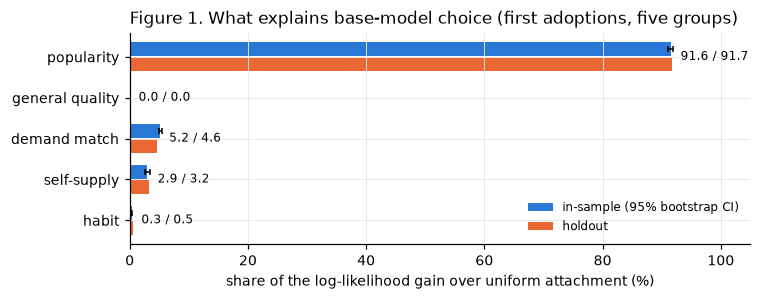

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.8))
order = list(T1.index)
y = np.arange(len(order))
ax.barh(y - 0.18, T1["in-sample"] * 100, height=0.34, color=C[0], label="in-sample (95% bootstrap CI)")
ax.errorbar(T1["in-sample"] * 100, y - 0.18, xerr=[(T1["in-sample"] - T1.lo) * 100, (T1.hi - T1["in-sample"]) * 100],
            fmt="none", ecolor="black", lw=1, capsize=2)
ax.barh(y + 0.18, T1["holdout"] * 100, height=0.34, color=C[1], label="holdout")
for i, (a, b) in enumerate(zip(T1["in-sample"], T1["holdout"])):
    ax.text(max(a, b) * 100 + 1.5, i, f"{100 * a:.1f} / {100 * b:.1f}", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis(); ax.set_xlim(0, 105)
ax.set_xlabel("share of the log-likelihood gain over uniform attachment (%)")
ax.set_title("Figure 1. What explains base-model choice (first adoptions, five groups)", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 1.2 每一组都显著：似然比检验
从 32 次子集拟合可以直接得到"去掉一组"的似然比统计量：
$$LR_g = 2\,[\ell(\hat\theta_{\mathcal G}) - \ell(\hat\theta_{\mathcal G\setminus g})] = 2\,[G(\mathcal G) - G(\mathcal G\setminus g)],$$
自由度是该组的特征数。它在正文中的作用是**把"显著"与"重要"分开**：每一组都显著，所以问题不是"开发者是否回应适合"，而是"适合能解释多少选择"。

In [4]:
fits, groups = P5["fits"], P5["groups"]
G = lambda S: fits[frozenset(S)]["ll"] - fits[frozenset()]["ll"]
allg = list(groups)
from scipy.stats import chi2
lr = []
for g in allg:
    st_ = 2 * (G(allg) - G([h for h in allg if h != g]))
    df = len(groups[g])
    lr.append(dict(group=LAB[g], features=df, LR=st_, p=chi2.sf(st_, df) if df else np.nan))
show(pd.DataFrame(lr).round(2))
info = P5["info"]; h = P5["nofe"]["hold"]
print(f"holdout: gain {h['mean_ll'] - P5['u0h']:.3f} nats/choice (x{np.exp(h['mean_ll'] - P5['u0h']):,.0f}), "
      f"top-1 {pct(h['top1'])}, top-10 {pct(h['top10'])}; pseudo-R2 in-sample {1 - P5['nofe']['ll'] / P5['u0']:.3f}")

,group,features,LR,p
0,popularity,17,1385593.89,0.0
1,general quality,1,25.38,0.0
2,demand match,6,15769.44,0.0
3,self-supply,1,42547.43,0.0
4,habit,1,9.60,0.0


holdout: gain 6.625 nats/choice (x754), top-1 14.2%, top-10 39.8%; pseudo-R2 in-sample 0.687


**写作要点（5.1）：**
1. **第一段直接给主结论，** 配图 1：流行 91.6%（91.1–91.9），适合 5.2%，自供给 2.9%，习惯 0.3%，质量 < 0.01%。
2. **紧接着给留出集。** 份额几乎不变，说明排序不是样本内拟合的产物。
3. **用一句话把"显著"和"重要"分开**（LR 检验）。
4. **潜类别结果一句话即可：** "按选择计，92% 的选择归于流行模式"，细节放附录 D（§8.4）。
5. **在这里第一次解释自供给：** 它是"选自己的模型"，主要是组织行为（5.5）。
6. **结尾提出 5.2 的问题：** 流行是不是质量的代理？

## 2. 5.2 流行是不是隐藏的质量？

benchmark 分数只覆盖很少的候选，所以"质量份额约 0"可能只是没测到质量。下面三种证据的强度依次递增。

### 2.1 上界：把枢纽 FE 全部算作质量
加入 500 个枢纽的固定效应（Section 4.5 定义 4），作为 Shapley 的额外玩家。FE 吸收枢纽所有不变的属性。把它全部算作质量，是对质量**最宽松**的解读。

In [5]:
show(tab("v2_bounds").round(4))
fit_ = tab("v2_pps_clogit_fit").set_index("model")
print(f"holdout gain: no FE {fit_.loc['full', 'hold_gain']:.3f}, with FE {fit_.loc['full + FE', 'hold_gain']:.3f} nats/choice")
fe5 = sh[(sh.variant == "FE as a player") & (sh.partition == "pop / fit / ...")].pivot(index="group", columns="measure", values="share")
show((fe5 * 100).round(2))

,bound,fit,popularity,fe_share,q,ratio_fit_pop
0,lower (no FE; quality = bench_z only),0.0520,0.9164,NaN,NaN,0.0568
1,FE all quality (in-sample; old-style upper bound),0.4598,0.5096,0.4206,NaN,0.9025
2,"external quality (v2 average, controls), in-sa...",0.0702,0.8992,0.4206,0.0735,0.0781
3,FE all quality (holdout; old-style upper bound),0.3622,0.6029,0.3230,NaN,0.6007
4,"external quality (v2 average, controls), holdout",0.0629,0.9022,0.3230,0.0735,0.0697


holdout gain: no FE 6.625, with FE 6.632 nats/choice


measure,holdout,in-sample
group,,
FE,32.29,42.05
fit (quality + match),3.88,3.92
habit,0.44,0.27
popularity,60.24,50.92
self-supply,3.15,2.85


### 2.2 外部质量能解释 FE 的多少
用枢纽的外部质量（Open LLM Leaderboard v2 平均分、Arena 评分）回归 $\hat\phi_h$，控制参数量和再分发账号，并做噪声校正（Section 4.5 的噪声引理）。

In [6]:
qe = tab("v2_quality_ext")
show(qe[[c for c in ["source", "controls", "hubs", "share_of_fe", "r2_noise_corrected", "quality_part_share"] if c in qe]].round(3))

,source,controls,hubs,share_of_fe,r2_noise_corrected,quality_part_share
0,v2 average,-,140,0.280,0.021,0.021
1,v2 average,redistributor,140,0.280,0.036,0.028
2,v2 average,redistributor+lparams,118,0.236,0.043,0.073
3,arena rating,-,49,0.098,0.211,0.211
4,arena rating,redistributor,49,0.098,0.390,0.131
5,arena rating,redistributor+lparams,41,0.082,0.381,0.216
6,native model-index,-,9,0.018,0.078,0.078
7,native model-index,redistributor,9,0.018,0.078,0.078
8,native model-index,redistributor+lparams,9,0.018,0.087,0.265
9,v2 average + arena (both covered),-,28,0.056,0.065,0.065


### 2.3 质量固定时：同权重副本
有 638 次首次采纳满足两个条件：候选集中同时有两个**同一份权重**的副本（权重哈希相同，由不同账号发布），并且其中一个被选中。质量在构造上完全相同。用两个副本的特征差做条件 logit，看是什么让一个副本胜出。

In [7]:
show(tab("v2_identical_pairs").round(4))

,quantity,value,se
0,choices with both copies in the set and one ch...,638.0000,NaN
1,coef d_log_deg,-0.0840,0.0960
2,coef d_lrec30,0.8423,0.0843
3,coef d_redist,-0.3869,0.0899
4,share of choices where the chosen copy has the...,0.4859,NaN


**怎么读：**
- **上界：** 即使把全部 FE 算作质量，流行仍占约 51%（样本内）。FE 几乎不改善样本外预测（6.625 → 6.632 nats）。
- **外部质量：** 只能解释 FE 方差的约 7%（118 个被覆盖的枢纽，噪声校正后）。按此拆分，适合份额只升到 7.0%。
- **同权重副本：**
  - 胜出的是近 30 天采纳更多的副本（系数 0.84，标准误 0.08），而不是总采纳更多的副本（−0.08，标准误 0.10）；
  - 被选副本的总 degree 更高的比例只有 48.6%，相当于抛硬币。

**写作要点（5.2）：**
- **三层证据的顺序：** 上界 → 外部质量 → 质量固定。
- **以副本结果收尾，并用它过渡到 5.3：** "质量固定时，起作用的不是总采纳，而是近期采纳。这提示'流行'这个组内部的结构很重要。"
- **待办：** benchmark 只覆盖 118/500 个枢纽，代表性需要讨论。

## 3. 5.3 流行由什么构成：大部分不是累积优势（新）

### 3.1 设计
把流行组拆成六个玩家，加上其余四组合并成的"非流行"玩家，一共七个玩家，做 $2^7=128$ 次子集拟合的 Shapley 分解。全部首次采纳，20 次按作者的乘数 bootstrap。

| 玩家 | 特征 | 含义 |
|---|---|---|
| 是否被采纳过（extensive） | `has_deg` | 有没有人用过：使用门槛 |
| 累积（cumulative） | `log_deg` | 总采纳数：经典优先连接 |
| 动量（momentum） | `lrec30` | 近 30 天的采纳 |
| 生命周期（lifecycle） | `log_age`、`legacy` | 年龄与旧代模型 |
| 可见度（visibility） | `major_org`、`redistributor`、`lquant`、缺失标记、`lib_*` | 品牌、再分发、量化版本、库 |
| 局部（local） | `lco2`、`ds_couse` | 两跳共同使用者、数据集共同使用 |
| 非流行 | 质量、匹配、自供给、习惯 | 合并为一个玩家 |

In [8]:
ps = tab("v2x_popsplit_full").set_index("group")
PSL = {"extensive": "used at all (has_deg)", "cumulative": "cumulative adoptions (log_deg)",
       "momentum": "momentum, 30 days (lrec30)", "visibility": "visibility (org, redistribution, quant, library)",
       "local": "local (co-users, dataset co-use)", "lifecycle": "lifecycle (age, legacy)", "nonpop": "all non-popularity groups"}
ps = ps.loc[["extensive", "cumulative", "momentum", "visibility", "local", "lifecycle", "nonpop"]]
show((ps[["share", "lo", "hi", "hold_share"]] * 100).round(2).rename(index=PSL))
print(f"popularity total in the 7-player game: {100 * (1 - ps.loc['nonpop', 'share']):.1f}% "
      f"(five-group game: {100 * T1.loc['popularity', 'in-sample']:.1f}%); bootstrap reps {int(ps.reps.iloc[0])}")
for f in ["has_deg", "log_deg", "lrec30", "major_org", "redistributor"]:
    r = m1.loc[f] if f in m1.index else None
    extra = f"; multiplier on (1+d) {r.multiplier:,.1f} [{r.mult_lo:,.1f}, {r.mult_hi:,.1f}] (dx = {r.dx:.3g})" if r is not None else ""
    print(f"{f:14s} coef {cf.loc[f, 'coef']:.3f} (se {cf.loc[f, 'se_cl']:.3f}){extra}")

,share,lo,hi,hold_share
group,,,,
used at all (has_deg),20.32,20.05,20.53,19.72
cumulative adoptions (log_deg),23.45,23.22,23.61,24.52
"momentum, 30 days (lrec30)",24.86,24.54,25.16,23.42
"visibility (org, redistribution, quant, library)",17.19,16.91,17.54,18.49
"local (co-users, dataset co-use)",4.82,4.53,5.03,3.35
"lifecycle (age, legacy)",2.53,2.31,2.72,3.57
all non-popularity groups,6.84,6.54,7.28,6.93


popularity total in the 7-player game: 93.2% (five-group game: 91.6%); bootstrap reps 20
has_deg        coef 4.637 (se 0.081); multiplier on (1+d) 705,194.7 [230,466.5, 2,157,795.6] (dx = 1)
log_deg        coef 0.344 (se 0.012)
lrec30         coef 0.605 (se 0.015); multiplier on (1+d) 8.5 [6.7, 10.8] (dx = 1.22)
major_org      coef 0.650 (se 0.031); multiplier on (1+d) 6.6 [5.5, 8.0] (dx = 1)
redistributor  coef 0.741 (se 0.040); multiplier on (1+d) 8.6 [6.3, 11.7] (dx = 1)


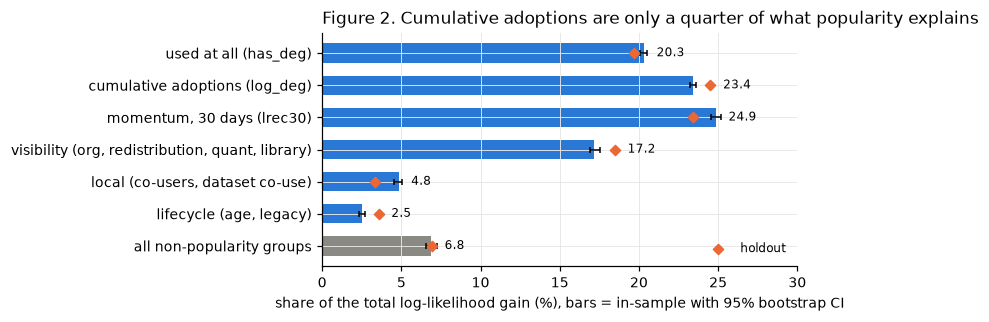

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3))
yy = np.arange(len(ps))
cols = [C[0]] * 6 + [GRAY]
ax.barh(yy, ps.share * 100, color=cols, height=0.6)
ax.errorbar(ps.share * 100, yy, xerr=[(ps.share - ps.lo) * 100, (ps.hi - ps.share) * 100], fmt="none", ecolor="black",
            lw=1, capsize=2)
ax.scatter(ps.hold_share * 100, yy, marker="D", s=22, color=C[1], zorder=3, label="holdout")
for i, v in enumerate(ps.share):
    ax.text(max(v, ps.hold_share.iloc[i]) * 100 + 0.8, i, f"{100 * v:.1f}", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels([PSL[g] for g in ps.index]); ax.invert_yaxis(); ax.set_xlim(0, 30)
ax.set_xlabel("share of the total log-likelihood gain (%), bars = in-sample with 95% bootstrap CI")
ax.set_title("Figure 2. Cumulative adoptions are only a quarter of what popularity explains", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 3.2 怎么读
**1. 累积优势只占约四分之一。**
- 经典优先连接（总采纳数）只占全部增益的 23.4%（23.2–23.6）。
- 主模型中 `log_deg` 的系数是 0.34，即 $P\propto d^{0.34}$，远低于 BA 模型的 1。单独估计累积项时，系数也只有 0.70（§7.1）。

**2. 另外三块同样大。**
- **近期动量：** 24.9%（24.5–25.2）。
- **使用门槛：** "是否被采纳过"占 20.3%。`has_deg` 的系数是 4.64，从"没人用过"到"有人用过"，概率约乘以 100 倍。
- **平台可见度：** 品牌、再分发账号、量化版本、库，合计 17.2%。

**3. 动量和累积哪个更大，这里分不出来。**
- 样本内动量略高（24.9 对 23.4，区间不重叠），留出集上反过来（23.4 对 24.5）。
- 正文只能写"各约四分之一"。动量更重要的证据来自另外两处：
  - 质量固定时（5.2 副本），只有动量起作用；
  - 生成集中时（Section 6），两个模拟器中去掉动量都使集中明显下降。

**4. 关于博弈划分的脚注。** 七个玩家的博弈中，流行合计 93.2%，五组博弈中是 91.6%。Shapley 值对玩家的拆分不是不变的：把一个玩家拆细，会改变它与其他玩家的交互项的分配。所以：
- 正文报告拆分时，用"占全部增益的份额"；
- 加一个脚注说明这 1.6 个百分点的差异。

**5. 稳定性。** 从 10% 样本到全量，每个子组的份额变化不超过 1 个百分点（附录 D，§8.3）。

### 3.3 写作要点（5.3）
- **开头承接 5.2：** "5.2 显示质量固定时近期采纳起作用而总采纳不起作用。这一节问：'流行'这个组到底由什么构成？"
- **主体：** 图 2 加一段读法，强调"累积优势只是四分之一"和"$d^{0.34}$"。
- **EC 含义（一句，详细讨论放 Section 7）：** 从总采纳中学习质量（社会学习）预测的是累积项起作用；动量和门槛更像注意力、羊群或"可用性证明"。
- **结尾引出 Section 6：** "这些成分中，哪个生成了观察到的集中？"
- **不要做的：** 不要说"动量最重要"；不要把拆分说成因果。

## 4. 5.4 适合：被看重、是开发者特有的，但很少起决定作用

### 4.1 问题：匹配"每单位很值钱"，为什么只解释 5%？
有两个数字，先分别说清楚它们是什么。

**(a) "相当于 degree 乘以约 246 倍"是一个边际替代率（MRS）。**

条件 logit 的效用 $V_{kl}=\theta^\top x_{kl}$ 以对数几率为单位。两个候选的效用相差 $\Delta V$，被选概率之比就是 $e^{\Delta V}$。不同特征的单位不同：`task_hist` 是 0/1，`log_deg` 是 $\log(1+d)$。所以系数不能直接比大小，要先换到同一个单位上。

这里问的是："`task_hist` 从 0 变为 1 带来的效用，相当于 $\log(1+d)$ 增加多少？"

$$\text{MRS}=\frac{\hat\theta_{\texttt{task\_hist}}\cdot\Delta x}{\hat\theta_{\texttt{log\_deg}}}=\frac{1.896\times 1}{0.344}=5.51 .$$

$\log(1+d)$ 增加 5.51，等于把 $(1+d)$ 乘以 $e^{5.51}\approx 246$。
- 二值特征取 $\Delta x=1$，连续特征取一个标准差。
- 95% 区间 [149, 407] 用 delta 方法，在按作者聚类的协方差上计算。来源是 `v2_robust.py` 的 `part_mrs`，表 `v2_mrs`。

**例子：** 其他特征都相同时，下面两个候选被选的概率相同：
- 已有 9 个子模型（$1+d=10$），任务出现在作者历史中；
- 任务不匹配，但有约 2,460 个子模型。

**两点注意：**
- **倍数大，很大程度上是因为参照物"便宜"。** `log_deg` 的系数只有 0.34，强烈次线性：degree 翻一倍，效用只增加 $0.34\times\ln 2\approx0.24$。换一个参照，倍数就变。
  - 以 30 天动量 `lrec30` 为参照：$1.896/0.605=3.13$，相当于把 $(1+\text{近 30 天的子模型数})$ 乘以 $e^{3.13}\approx 23$。
  - 所以"×246"只是单位换算，说明不了"匹配比流行重要"。这正是 Section 4.4 不直接解释系数的理由 (i)。
- **换算时其他特征都不变。** 现实中 degree 高的模型通常 `has_deg`=1、`lrec30` 也高。所以这不是"把某个真实模型的 degree 乘以 246"的反事实。

**(b) "只解释 5% 的增益"是一个 Shapley 份额。**

"增益"是对数似然相对于均匀连接（$\theta=0$，市场中每个模型被选的概率相同）的提高：$G=\ell(\hat\theta)-\ell(0)$。
- 训练集有 117,509 次首次采纳，$G=$ 789,866 nats，平均每次 6.72 nats。也就是说，模型给真实父模型的概率平均是均匀猜测的 $e^{6.72}\approx 830$ 倍。留出集上是 6.62 nats，约 754 倍，即 5.1 中的"×754"。
- Shapley 值把 $G$ 分给五组：每组的值是它在全部加入顺序（32 次拟合）下的平均边际增益。
- 需求匹配得到 40,985 nats，即 **5.19%**（95% 区间 4.97–5.50%，留出集 4.58%）；流行得到 91.6%。

**(c) 两者为什么不矛盾。**
- 系数（以及由它算出的 MRS）回答的是：两个候选在匹配上相差一个单位时，概率差多少。
- Shapley 份额回答的是：在实际的候选集里，这种差异出现得有多频繁、有多大、是否指向被选者。

如果同一个候选集里大多数候选的匹配程度相同，匹配的系数再大也区分不了它们。下面 4.2 从"指数在候选集内的变异"、4.3 从"并列"两个角度检验这一点。

In [10]:
for f in ["task_hist", "lang_hist", "ds_task", "txt_sim"]:
    if f in m1.index:
        r = m1.loc[f]
        print(f"{f:10s} coef {cf.loc[f, 'coef']:.3f}; MRS vs log_deg = {np.log(r.multiplier):.2f} -> (1+d) x {r.multiplier:,.1f}  [{r.mult_lo:,.1f}, {r.mult_hi:,.1f}]  (dx = {r.dx:.3g})")
m2 = mrs[mrs.ref == "lrec30"].set_index("feature")
print(f"task_hist vs lrec30: (1 + recent) x {m2.loc['task_hist', 'multiplier']:.1f}")
g = tab("v2s_P5_shapley"); g = g[(g.variant == "no FE") & (g.partition == "groups")]
gi, gh = g[g.measure == "in-sample"].set_index("group"), g[g.measure == "holdout"].set_index("group")
n_tr = P5["info"]["n_train"]
G = gi.total.iloc[0]
print(f"gain G = {G:,.0f} nats over {n_tr:,} training choices = {G / n_tr:.2f} nats/choice (x{np.exp(G / n_tr):,.0f}); "
      f"holdout {gh.total.iloc[0]:.2f} nats/choice (x{np.exp(gh.total.iloc[0]):,.0f})")
print(f"demand match: {gi.loc['demand match', 'value']:,.0f} nats = {pct(gi.loc['demand match', 'share'], 2)} "
      f"[{pct(gi.loc['demand match', 'lo'], 2)}, {pct(gi.loc['demand match', 'hi'], 2)}]; holdout {pct(gh.loc['demand match', 'share'], 2)}")

task_hist  coef 1.896; MRS vs log_deg = 5.51 -> (1+d) x 246.2  [148.9, 407.2]  (dx = 1)
lang_hist  coef 0.251; MRS vs log_deg = 0.73 -> (1+d) x 2.1  [1.7, 2.5]  (dx = 1)
ds_task    coef 0.883; MRS vs log_deg = 2.57 -> (1+d) x 13.0  [6.7, 25.4]  (dx = 1)
txt_sim    coef 1.687; MRS vs log_deg = 0.14 -> (1+d) x 1.2  [0.8, 1.6]  (dx = 0.029)
task_hist vs lrec30: (1 + recent) x 23.0
gain G = 789,866 nats over 117,509 training choices = 6.72 nats/choice (x830); holdout 6.62 nats/choice (x754)
demand match: 40,985 nats = 5.19% [4.97%, 5.50%]; holdout 4.58%


### 4.2 证据一：各组指数在候选集内的变异

**做法：**
1. 对训练集的每次选择 $k$，取它的 PPS 候选集 $\mathcal D_k$。平均约 300 个候选，其中大量是从未被使用过的模型。
2. 对每组 $g$ 计算效用指数 $I_{g,kl}=\hat\theta_g^\top x_{kl,g}$，即这组特征对候选 $l$ 的效用贡献，用主模型（不含 FE）的系数。
3. 在每个候选集内计算这个指数的标准差、极差，以及被选者比集内平均高多少。
4. 对 117,509 次选择取中位数或平均。

**为什么算这个：** logit 的选择概率只取决于同一候选集内的效用差。一组特征能解释多少选择，取决于两件事：
- 这组指数在同一候选集内差别有多大；
- 被选者是否落在高的一端。

系数只是第一件事的一半：系数乘以特征在集内的变异，才是效用的变异。这张表直接度量这两件事。

In [11]:
from hfpa.v2data import load_rows, split
rows, ch = load_rows("v2_pps", "planA")
tr, _ = split(rows, ch)
tr = tr.sort_values("choice_id", kind="stable").reset_index(drop=True)
feats, b = P5["feats"], P5["nofe"]["coef"]
X = tr[feats].to_numpy(np.float64)
cid = tr.choice_id.to_numpy(); st = np.r_[0, np.flatnonzero(np.diff(cid)) + 1]; ln = np.diff(np.r_[st, len(cid)])
I = {g: X[:, [feats.index(f) for f in v]] @ b[[feats.index(f) for f in v]] for g, v in groups.items() if v}
chosen = tr.chosen.to_numpy() == 1
rows_out = []
for g, v in I.items():
    mu = np.add.reduceat(v, st) / ln
    sd = np.sqrt(np.maximum(np.add.reduceat(v * v, st) / ln - mu ** 2, 0))
    rng_ = np.maximum.reduceat(v, st) - np.minimum.reduceat(v, st)
    adv = v[chosen] - mu                      # chosen minus set mean (choices are in the same order)
    rows_out.append(dict(group=LAB[g], within_sd_median=np.median(sd), within_sd_mean=sd.mean(),
                         within_range_median=np.median(rng_), chosen_minus_mean=adv.mean(),
                         share_sets_constant=(sd < 1e-9).mean()))
VAR = pd.DataFrame(rows_out).set_index("group")
print(f"{len(st):,} training choices; {len(tr):,} rows ({len(tr) / len(st):.0f} candidates per set)")
show(VAR.round(3))
VAR["odds_1sd"] = np.exp(VAR.within_sd_median); VAR["odds_chosen"] = np.exp(VAR.chosen_minus_mean)
show(VAR[["odds_1sd", "odds_chosen"]].round(2).rename(columns={"odds_1sd": "odds ratio, 1 within-set SD",
                                                              "odds_chosen": "odds ratio, chosen vs set mean"}))
del X

117,509 training choices; 35,189,821 rows (299 candidates per set)


,within_sd_median,within_sd_mean,within_range_median,chosen_minus_mean,share_sets_constant
group,,,,,
popularity,3.471,3.214,15.121,8.264,0.000
general quality,0.003,0.005,0.046,0.000,0.397
demand match,0.292,0.446,1.021,0.474,0.342
self-supply,0.000,0.036,0.000,0.350,0.924
habit,0.000,0.004,0.000,0.003,0.644


,"odds ratio, 1 within-set SD","odds ratio, chosen vs set mean"
group,,
popularity,32.17,3881.69
general quality,1.00,1.00
demand match,1.34,1.61
self-supply,1.00,1.42
habit,1.00,1.00


**表怎么读：** 单位都是效用，即对数几率；$e^{x}$ 就是几率之比。各列含义：

| 列 | 含义 |
|---|---|
| `within_sd_median` / `within_sd_mean` | 候选集内指数标准差的中位数 / 平均 |
| `within_range_median` | 集内最大值减最小值，取中位数 |
| `chosen_minus_mean` | 被选者的指数减集内平均，对所有选择取平均 |
| `share_sets_constant` | 指数在集内完全不变的候选集比例；在这些集合里，这一组区分不了任何候选 |

逐组看：
- **流行：**
  - 集内标准差的中位数是 3.47：相差一个标准差，几率约差 $e^{3.47}\approx 32$ 倍；
  - 极差 15.1，即从未被使用过的模型到头部枢纽；
  - 被选者平均比集内平均高 8.26，几率约 3,900 倍；
  - 没有一个集合的流行指数是常数。
- **需求匹配：**
  - 标准差的中位数只有 0.29（约 1.34 倍），极差 1.02；
  - 被选者平均只高 0.47（约 1.6 倍）；
  - 34% 的集合中匹配指数完全不变：作者没有可用的需求信号，或者所有候选的匹配特征相同。
- **自供给：** 92% 的集合不变，因为候选集中没有作者自己的模型。但出现时差别很大，所以被选者平均仍高 0.35。
- **质量：** 标准差约 0.003，几乎为零；40% 的集合不变，因为缺 benchmark。
- **习惯：** 64% 的集合不变，变异接近零。

**结论：**
- `task_hist` 的系数（1.90）大，但匹配特征大多是 0/1，同一个候选集里往往有很多候选同时满足（同任务的模型很多），所以匹配指数在集内的变异很小。
- 流行指数由 `has_deg`（4.64）、`log_deg`、`lrec30` 等组成，在"从未被使用"到"头部枢纽"之间相差 15 个单位。
- 粗略地看，被选者优势之比（8.26 : 0.47 ≈ 18 : 1）与 Shapley 份额之比（91.6 : 5.2 ≈ 18 : 1）在同一个量级。这不是恒等式，只说明份额主要反映集内的变异。这也回答了 §11 的追问"流行份额高是不是因为流行特征多"：份额高的原因是流行指数在候选之间差别大，并且指向被选者。

**局限：** 这张表是描述性的：
- 指数没有加 $-\log\pi$ 偏移；
- 候选集是抽样集合，不是全市场；
- 集内的变异包括"用过 / 没用过"这一条边界（4.4 把它单独拿掉检验）。

### 4.3 证据二：多少候选同时"匹配最好"，以及被选者是哪一类

**做法：** 来源是 `v2_welfare.py --classify`，表 `v2_classify`；用全部 133,047 次首次采纳（训练集加留出集）。
1. **比较集合：** 候选集中已被使用过的候选（$d>0$，即 $\pi=1$ 的确定层和正 degree 的泊松抽样）加上被选者，平均 47.7 个（中位数 51）。去掉从未被使用的模型，是为了只在"像样的竞争者"之间比较。否则"流行最高"几乎总是成立，问题就变得平凡。
2. **两个指数：** 对每个候选算匹配指数 $I_{\text{match}}$ 和流行指数 $I_{\text{pop}}$，与 4.2 相同。
3. **被选者是不是"最好"：** 设 $T_k$ 是集合中取到匹配指数最大值的候选个数（并列数），则

   $$p^{\text{fit}}_k=\frac{\mathbb 1\big[I_{\text{match},kj_k}=\max_l I_{\text{match},kl}\big]}{T_k}.$$

   如果 5 个候选并列匹配最好，被选者是其中之一，那么随机挑一个作为"匹配最好的候选"时，挑中被选者的概率是 1/5。$p^{\text{pop}}_k$ 同理。流行指数是连续的，几乎不会并列（平均 1.0001 个），所以 $p^{\text{pop}}_k$ 基本是 0 或 1。
4. **四类的概率：** 两次随机打破相互独立，所以：

   | 类型 | 概率 |
   |---|---|
   | 适合型 | $p^{\text{fit}}(1-p^{\text{pop}})$ |
   | 流行型 | $(1-p^{\text{fit}})\,p^{\text{pop}}$ |
   | 两者都是 | $p^{\text{fit}}p^{\text{pop}}$ |
   | 都不是 | $(1-p^{\text{fit}})(1-p^{\text{pop}})$ |

5. **期望份额：** 把每次选择的这些概率加总，得到 `expected_n`（期望个数）；除以选择数就是期望份额。
6. **没有需求信号的选择单列**，记为 "no demand signal"：作者无历史、无可用数据集、卡片文本不足，或者集合内匹配指数完全不变。共 46,689 次，占 35%，这些选择谈不上"匹配最好"。`share_with_signal` 以有信号的 86,358 次为分母，正文用这一列。

**为什么用期望而不直接分类：** 如果规定"被选者在并列组里就算适合型"，那么匹配特征大多是 0/1 时，一个集合里常常有一大批候选并列最好，适合型会被系统性高估。随机打破问的是："如果必须从并列者里指定一个为'最佳匹配'，它恰好是被选者的概率有多大？"这样，"匹配最好"的标准与流行一样严格，都是集合中唯一的一个。

In [12]:
show(tab("v2_classify").round(4))
K = pd.read_parquet(f"{CH}/v2_est/classify.parquet"); s = K.signal
print(f"choices {len(K):,}; with demand signal {s.sum():,}; comparison-set size mean {K.n.mean():.1f}, median {K.n.median():.0f}")
print(f"random-choice benchmark (each type of 'best'): mean 1/n = {pct((1 / K.n[s]).mean())}")
print(f"chosen parent ties at the max match index: {pct((K.p_fit[s] > 0).mean())} of choices "
      f"(random benchmark: mean T/n = {pct((K.ties_match[s] / K.n[s]).mean())})")
print(f"sets with more than one candidate at the max match: {pct((K.ties_match[s] > 1).mean())}; "
      f"number tied: mean {K.ties_match[s].mean():.1f}, median {K.ties_match[s].median():.0f}; "
      f"popularity ties: mean {K.ties_pop[s].mean():.4f}")
print(f"chosen parent's popularity index below the set max: median {K.pop_gap[s].median():.2f}; "
      f"match index below the set max: median {K.fit_gap[s].median():.2f}")

,type,expected_n,share_all,share_with_signal,mean_fit_gap
0,fit-type,7537.2044,0.0567,0.0873,0.0000
1,popularity-type,9972.6655,0.0750,0.1155,0.3802
2,both,621.3345,0.0047,0.0072,0.0000
3,neither,68226.7956,0.5128,0.7900,0.3715
4,no demand signal,46689.0000,0.3509,NaN,0.0000
5,(ties) choices where the chosen parent ties ot...,65800.0000,NaN,NaN,NaN
6,(ties) mean number tied at the max match index...,7.9370,NaN,NaN,NaN


choices 133,047; with demand signal 86,358; comparison-set size mean 47.7, median 51
random-choice benchmark (each type of 'best'): mean 1/n = 3.0%
chosen parent ties at the max match index: 29.0% of choices (random benchmark: mean T/n = 17.9%)
sets with more than one candidate at the max match: 61.9%; number tied: mean 7.9, median 5; popularity ties: mean 1.0001
chosen parent's popularity index below the set max: median 3.00; match index below the set max: median 0.15


**表怎么读：** 分母是有需求信号的 86,358 次选择。
- **四类份额：** 适合型 8.7%，流行型 11.6%，两者都是 0.7%，都不是 79.0%。合起来，被选者是唯一最匹配者的占 9.4%（宏 `clsFitAny`），是最流行者的占 12.3%（`clsPopAny`）。
- **随机基准：** 如果在约 48 个候选中随机选一个，它是最匹配者的期望概率是 $E[1/n]\approx 3.0\%$，是最流行者也是 3.0%。匹配和流行都把这个概率提高到基准的 3–4 倍，所以两者都起作用。
- **并列是匹配的问题所在：**
  - 62% 的集合中不止一个候选并列匹配最好，平均 7.9 个（中位数 5），约占集合的 18%；
  - 被选者落在"并列最好"那一组的比例是 29%，随机选是 18%。匹配确实把被选者推向了这一组；
  - 但组内谁被选中，匹配说不出来，打破并列后只剩 9.4%。
  
  流行指数则从不并列，总能排出唯一的第一。
- **"都不是"占 79%：** 大多数被选者既不是最匹配的，也不是最流行的。logit 的选择是概率性的：流行显著提高被选概率，但"最热门的那一个"只在 12% 的选择中胜出。被选者的流行指数比集合最大值低 3.0 个单位（中位数）。`mean_fit_gap` 列：在"都不是"和"流行型"的选择中，被选者的匹配指数平均比最好的低约 0.37，相当于约 1.45 倍的几率。

**结论：** "fit narrows the field; popularity picks the winner" 的准确含义是：
- 匹配把候选缩小到一组同样匹配的候选（平均约 8 个），这一步有用，被选者落在其中的概率从 18% 升到 29%；
- 匹配本身无法在这组内部排序，候选之间的效用差主要来自流行（4.2）。

**注意：** 这张表没有直接回答"在并列最好的那组里，被选者是不是最流行的"。需要的话可以补算（在 35M 行上重算组内流行排名，一个 CPU 作业）。在那之前，正文不要写"在并列者中流行决定赢家"，只写上面两点。

### 4.4 证据三：集约边际，即只在已被使用过的候选之间
**替代解释（两阶段）：** 流行只决定一个候选能否进入考虑范围（有没有人用过）；在已被使用过的候选之间，由适合决定。

**检验：** 把候选集限制为 $d\ge1$ 或 $d\ge10$ 的候选，并且只保留被选者也满足这个条件的选择，重新做五组分解。

In [13]:
mg = tab("v2x_margin"); mg = mg[mg.frac == mg.frac.max()]
show(mg.pivot_table(index=["min_deg", "kept", "set_size"], columns="measure", values=["popularity", "fit", "self", "habit"]).round(4))

fit           habit         popularity            self        
measure                    hold_ll      ll hold_ll      ll    hold_ll      ll hold_ll      ll
min_deg kept     set_size                                                                    
1       0.886519 45.998099  0.0512  0.0541  0.0029  0.0022     0.9455  0.9431  0.0003  0.0006
10      0.793114 37.059250  0.0605  0.0559  0.0056  0.0043     0.9336  0.9396  0.0003  0.0002

**怎么读：** 两阶段解释不成立。
- 只看 $d\ge1$ 的候选（保留 89% 的选择，候选集平均 46 个）：流行仍占 94.3%，适合 5.4%。
- 只看 $d\ge10$ 的候选（保留 79%）：流行 94.0%，适合 5.6%，与全集合几乎相同。

即使在已被使用过的候选之间，流行仍然决定赢家。

### 4.5 证据四：适合是开发者特有的需求吗？（donor 安慰剂）
**替代解释：** 匹配份额可能只是共同潮流。匹配特征可能只捕捉到"这个月、这个模态大家都在做什么"，而不是"这个开发者需要什么"。例如某个月文本生成领域的作者普遍在做同一种语言的对话模型，那么与这类任务相符的候选对谁都"匹配"。

**做法：** 来源是 `v2_features.py --placebo`（donor 特征）和 `v2_bounds.py --placebo` / `--placebo-joint`。
1. **找 donor：** 对每次首次采纳 $k$（作者 $a$，月份 $t$，模态 $m$），在同一"月份 × 模态"格子里随机抽另一位作者的一次首次采纳 $k'$（seed 0）。训练集中有 donor 的选择共 117,497 次，几乎是全部（117,509）。
2. **换需求，不换候选：** 保持 $k$ 的候选集，以及流行、质量、自供给、习惯特征不变，只把六个匹配特征（`size_dist`、`task_hist`、`lang_hist`、`ds_lang`、`ds_task`、`txt_sim`）用 donor 的需求重算：donor 子模型的任务、语言、规模，donor 作者的历史，donor 声明的数据集，donor 的卡片文本。
3. **两个版本：**
   - **替换**（`v2_placebo`）：用 donor 的匹配代替自己的匹配，重做 Shapley。
   - **联合**（`v2_placebo_joint`）：自己的匹配和 donor 的匹配同时进入一个模型，donor 的匹配作为额外的一个 Shapley 玩家。

**意义：** donor 与开发者处在同一个月、同一个模态，面对同样的潮流，但没有这个开发者特有的需求。所以：
- 如果 donor 的匹配和自己的一样能解释选择，匹配份额就只是潮流；
- 如果 donor 的匹配几乎为零，匹配份额就完全是个体需求；
- 联合模型中，自己的匹配份额是扣除共同潮流之后剩下的部分。

In [14]:
show(tab("v2_placebo").round(4))
show(tab("v2_placebo_joint").round(4))
show(tab("v2_placebo_joint_coef").round(3))

,demand,group,share,total_gain,n
0,real,popularity,0.9164,789843.683,117497
1,real,general quality,0.0001,789843.683,117497
2,real,demand match,0.0520,789843.683,117497
3,real,inertia,0.0316,789843.683,117497
4,placebo,popularity,0.9338,782281.758,117497
5,placebo,general quality,0.0001,782281.758,117497
6,placebo,demand match,0.0312,782281.758,117497
7,placebo,inertia,0.0350,782281.758,117497


,group,share,value,total_gain,n
0,popularity,0.8996,710782.5719,790138.2539,117497
1,general quality,0.0001,40.0940,790138.2539,117497
2,demand match,0.0450,35539.3715,790138.2539,117497
3,inertia,0.0315,24898.6567,790138.2539,117497
4,placebo (donor) match,0.0239,18877.5598,790138.2539,117497


,param,coef,se_cl
0,size_dist,-0.233,0.015
1,task_hist,1.929,0.046
2,lang_hist,0.156,0.035
3,ds_lang,0.307,0.056
4,ds_task,0.927,0.108
5,txt_sim,1.717,2.163
6,pl_size_dist,0.036,0.007
7,pl_task_hist,-0.166,0.017
8,pl_lang_hist,0.167,0.014
9,pl_ds_lang,0.211,0.035


**表怎么读：** 这里用的是早期的四组口径，`inertia` = 自供给 + 习惯。
- **第一张表（替换）：**
  - 真实需求下，匹配占 5.2%；换成 donor 的需求后仍有 3.1%。
  - 总增益只从 789,844 降到 782,282（−1%），流行从 91.6% 升到 93.4%。
  - 所以同月同模态的需求确实有共同成分，donor 的匹配也能解释一部分。
- **第二张表（联合）：**
  - 自己的匹配占 4.50%，donor 的匹配占 2.39%，流行 89.96%。
  - 与只有自己匹配的模型（5.20%、91.64%）相比，自己的匹配只少了 0.7 个百分点，流行却少了 1.7 个百分点。donor 的匹配拿走的主要是**流行**的份额。
- **第三张表（联合模型的系数）：**
  - 自己的 `task_hist` 为 1.93（单独模型中是 1.90），几乎不变。
  - donor 的 `task_hist` 是 −0.17，`ds_task` 是 −0.26，符号与"适合"相反。
  - donor 的语言类特征为正（`lang_hist` 0.17，`ds_lang` 0.21），说明同月同模态有共同的语言潮流；但这些系数都远小于自己的对应系数，且任务类特征为负。
  - 整体上，donor 的匹配更像"这个月这个模态什么热门"的流行代理，而不是需求。

**结论：** 共同潮流存在（donor 单独可以解释 3.1%），但它和流行重叠，不能替代自己的匹配。扣除共同潮流之后，自己的匹配仍有 4.5%，这部分是开发者特有的需求。

**注意：**
- **口径：** 这个检验用的是早期的四组口径和 v2 主模型的训练集，没有在五组口径下重跑。五组下匹配份额是 5.19%，与四组的 5.20% 几乎相同，自供给与习惯的拆分不涉及匹配特征，所以结论不受影响。
- **Shapley 值的含义：** 它不是"去掉某个玩家后的损失"。玩家之间相关时，加入一个新玩家会重新分配其他玩家的份额（§3 拆分流行时也出现过）。所以 4.5% 应读作"与 donor 的匹配分摊了重叠部分之后"自己的份额。
- **区间：** 这些份额没有 bootstrap 区间；donor 只抽了一次（seed 0）。
- 正文需要一句话交代 donor 的定义，并把两个数字（3.1%、4.5%）写成宏。

### 4.6 写作要点（5.4）
**顺序：**
1. 匹配的价值很高（×246），但要注明这是相对于 $\log(1+d)$ 的边际替代率；
2. 但匹配很少能区分候选：集内变异小，平均 7.9 个候选并列匹配最好；
3. 核心句："**fit narrows the field; popularity picks the winner**"，按 4.3 结论的两点来写；
4. 集约边际一句，排除两阶段解释，表放附录 D；
5. donor 安慰剂一段：剩下的适合是开发者特有的。

**措辞：** 在有需求信号的选择中，被选者恰好是集合中最流行者的只占 12.3%（随机基准 3%），两者都不是的占 79%。所以"跟随流行"是概率意义上的，不是"人人选最热门"。

## 5. 5.5 谁在跟随流行？

六类作者分别估计完整模型和 32 次子集拟合，各做 50 次 bootstrap。跨类型比较用份额，不用系数，因为 logit 的尺度在类型之间可以不同。

In [15]:
R = tab("v2s_robustness").set_index("config")
types = ["indiv_light", "indiv_mid", "indiv_heavy", "org_other", "org_redistributor", "org_major"]
TL = {"indiv_light": "individuals <10 models", "indiv_mid": "individuals 10-99", "indiv_heavy": "individuals >=100",
      "org_other": "other organizations", "org_redistributor": "re-distribution accounts", "org_major": "major organizations"}
cols = ["n_train", "authors", "popularity", "popularity lo", "popularity hi", "fit (quality + match)",
        "fit (quality + match) lo", "fit (quality + match) hi", "self-supply", "habit", "ratio fit / popularity"]
TT = R.loc[[f"P5_{t}" for t in types], cols].rename(index=lambda s: TL[s[3:]])
share_first = TT.n_train / TT.n_train.sum()
TT.insert(2, "share of first adoptions", share_first)
show(TT.round(4))
show(tab("v2s_hetero"))

,n_train,authors,share of first adoptions,popularity,popularity lo,popularity hi,fit (quality + match),fit (quality + match) lo,fit (quality + match) hi,self-supply,habit,ratio fit / popularity
config,,,,,,,,,,,,
individuals <10 models,60972,49758,0.5189,0.9707,0.9698,0.9714,0.0205,0.0199,0.0211,0.0078,0.0011,0.0211
individuals 10-99,25524,8428,0.2172,0.8525,0.8458,0.8563,0.0782,0.0759,0.0807,0.0602,0.0091,0.0917
individuals >=100,21753,762,0.1851,0.8287,0.8117,0.8444,0.1122,0.1074,0.1184,0.0539,0.0053,0.1354
other organizations,6964,2474,0.0593,0.8279,0.8009,0.8412,0.1040,0.0951,0.1265,0.0582,0.0098,0.1257
re-distribution accounts,2042,179,0.0174,0.8381,0.7922,0.8651,0.1478,0.1231,0.1838,0.0050,0.0090,0.1763
major organizations,254,34,0.0022,0.5878,0.5248,0.6790,0.1733,0.1581,0.1898,0.2154,0.0235,0.2949


,sample,types,ll_pooled,ll_by_type,lr,df,p,note
0,P,6,-359783.600475,-340704.545869,38158.109213,130,0.0,all types fitted
1,D,6,-607855.930198,-581225.693921,53260.472554,140,0.0,all types fitted


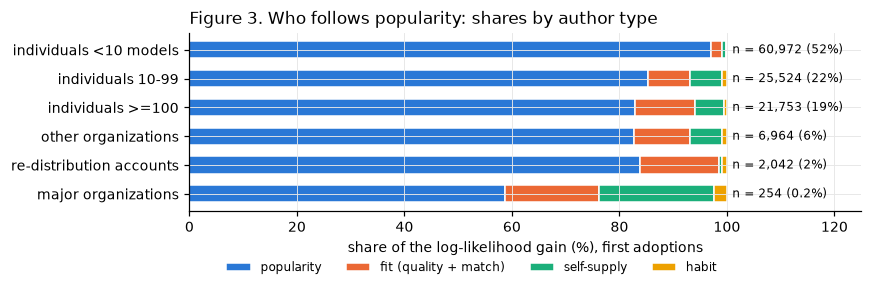

In [16]:
fig, ax = plt.subplots(figsize=(8, 3))
parts = [("popularity", C[0]), ("fit (quality + match)", C[1]), ("self-supply", C[2]), ("habit", C[3])]
left = np.zeros(len(TT))
yy = np.arange(len(TT))
for name, col in parts:
    v = TT[name].to_numpy() * 100
    ax.barh(yy, v, left=left, color=col, height=0.6, label=name, edgecolor="white", linewidth=1)
    left += v
for i, (n, s) in enumerate(zip(TT.n_train, TT["share of first adoptions"])):
    lab_s = f"{100 * s:.0f}%" if s >= 0.005 else f"{100 * s:.1f}%"
    ax.text(101, i, f"n = {int(n):,} ({lab_s})", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(TT.index); ax.invert_yaxis(); ax.set_xlim(0, 125)
ax.set_xlabel("share of the log-likelihood gain (%), first adoptions")
ax.set_title("Figure 3. Who follows popularity: shares by author type", loc="left")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.42, -0.42))
plt.tight_layout(); plt.show()

**怎么读：**
- **典型开发者几乎完全跟随流行：** 轻度个人占首次采纳的一半，流行占 97.1%，适合 2.1%。
- **适合份额随账号的规模和专业程度上升：** 从 7.8%（中等个人）到 17.3%（大机构）。
- **自供给是组织行为：** 大机构 21.5%，轻度个人 0.8%。
- **合并估计被显著拒绝：** $LR=38{,}158$，自由度 130。
- **与 5.1 的关系：** 主结果中 5.2% 的适合份额，主要来自少数高产账号和组织。

**写作要点（5.5）：**
- 配图 3。
- **措辞：** "fit matters more for experienced and organizational developers"。
- **样本量：** 大机构只有 254 次选择，提到时注明。
- **再分发账号是按行为定义的，** 需要在 Section 3 或附录 A 说明。
- 图中 "(0%)" 的标签已改为保留一位小数。

## 6. 5.6 稳健性（正文部分：样本选择）

正文只保留样本选择这一项，因为它回应"少数作者"这个最可能的质疑。其余检验放附录 D（§8），正文一句话列出。

判断规则是运行前确定的（Section 4.7）：
- 流行份额与主结果相差不超过 10 个百分点；
- 适合/流行比值在主结果的 1/3 到 3 倍之间。

In [17]:
main_cfg = ["P5", "P5top", "P5a", "D5", "D5raw", "D5a", "D5top", "U5"]
NM = {"P5": "first adoptions (main)", "P5top": "first adoptions, top 1% authors dropped",
      "P5a": "first adoptions, authors weighted equally", "D5": "all 24h decisions",
      "D5raw": "all decisions, no self-degree correction", "D5a": "all decisions, authors weighted equally",
      "D5top": "all decisions, top 1% dropped", "U5": "all uploads"}
RS = R.loc[[c for c in main_cfg if c in R.index], ["n_train", "authors", "popularity", "popularity lo", "popularity hi",
            "fit (quality + match)", "self-supply", "habit", "ratio fit / popularity", "d_pop_pts", "ratio_vs_main",
            "robust", "reps"]].rename(index=NM)
show(RS.round(4))

,n_train,authors,popularity,popularity lo,popularity hi,fit (quality + match),self-supply,habit,ratio fit / popularity,d_pop_pts,ratio_vs_main,robust,reps
config,,,,,,,,,,,,,
first adoptions (main),117509,61635,0.9158,0.9115,0.9191,0.0519,0.0292,0.0031,0.0567,0.0000,1.0000,True,50.0
"first adoptions, top 1% authors dropped",89305,60957,0.9421,0.9404,0.9432,0.0348,0.0206,0.0025,0.0369,2.6295,0.6510,True,50.0
"first adoptions, authors weighted equally",117509,61635,0.9698,0.9691,0.9704,0.0178,0.0113,0.0011,0.0183,5.4036,0.3228,False,50.0
all 24h decisions,176061,61670,0.7306,0.7222,0.7363,0.0314,0.0188,0.2192,0.0429,-18.5134,0.7573,False,50.0
"all decisions, no self-degree correction",176061,61670,0.7383,0.7301,0.7437,0.0311,0.0157,0.2148,0.0421,-17.7469,0.7432,False,50.0
"all decisions, authors weighted equally",176061,61670,0.9035,0.9023,0.9054,0.0098,0.0094,0.0773,0.0108,-1.2261,0.1907,False,50.0
"all decisions, top 1% dropped",117252,60985,0.7940,0.7907,0.7963,0.0172,0.0167,0.1721,0.0217,-12.1795,0.3827,False,50.0
all uploads,381311,61670,0.5138,0.4984,0.5267,0.0245,0.0076,0.4541,0.0476,-40.1982,0.8398,False,50.0


**怎么读：**
- **按规则，只有"去掉前 1% 作者"通过。** 但所有偏离的方向一致：
  - 加入重复选择后，习惯挤占流行（全部决策中 21.9%，全部上传中 45.4%）；
  - 作者等权或去掉头部后，适合进一步变小（1.8%、3.5%）。
- **没有任何口径让适合比主结果更重要。** 正文应写："流行主导在所有口径下都成立；主结果的适合份额是各口径中的偏高端。"
- **扣除自身 degree 的修正**改变份额不到 1 个百分点（D5 与 D5raw），正文一句。

**写作要点（5.6）：**
- 第一段：样本选择，配 `tab_samples` 的上半部分，并如实报告规则的结果。
- 第二段（一句）："候选集设计、需求信号子样本、文本门槛、旧卡片、10% 样本、潜类别的结果见附录 D，都不改变结论。"

## 7. 移交给 Section 6 和 Section 7 的结果

这些结果不回答"什么驱动选择"，而是回答"这种选择方式在网络层面和福利上意味着什么"。下面整理它们的现状和用法，供写 Section 6/7 时使用。

### 7.1 增长消融：哪个成分生成了集中（→ Section 6，与 5.3 呼应）
**设计：**
1. **重新估计：** 在全部首次采纳上，重新估计去掉某些流行项的五组模型，让其余系数调整。
2. **模拟：** 用各模型的流行系数，在全市场做带反馈的增长模拟（`v2_networks.SF`），5 个种子。真实的事件序列（谁、何时、哪个模态）保持不变，只重抽父模型。

第一轮小规模实验没有重新估计，只把系数设为 0。那样夸大了动量的作用，并且把年龄衰减的方向弄反了，所以这里只报告重新估计的版本。

In [18]:
show(tab("v2x_refit").round(4))
sr = tab("v2x_sfrefit").set_index("variant")
show(sr[["top10_mean", "top10_min", "top10_max", "eff_parents_mean", "gini_mean", "turnover_mean", "n_parents_mean"]].round(3))

,variant,ll,hold_mean_ll,hold_top10,coef_has_deg,coef_log_deg,coef_lrec30,coef_log_age
0,SF full (refit),-359783.6005,-3.4022,0.3985,4.6366,0.3443,0.6050,-0.5388
1,no momentum (refit),-377699.0365,-3.5022,0.3172,4.7962,0.7867,0.0000,-0.7867
2,no age decay (refit),-369208.5469,-3.5432,0.3691,4.6758,0.1561,0.7723,0.0000
3,cumulative only (refit),-400561.3047,-3.7774,0.2864,4.5445,0.6971,0.0000,0.0000


,top10_mean,top10_min,top10_max,eff_parents_mean,gini_mean,turnover_mean,n_parents_mean
variant,,,,,,,
REAL,0.219,0.219,0.219,838.668,0.854,0.464,15450.0
SF full (refit),0.237,0.215,0.265,2646.663,0.697,0.480,20256.2
cumulative only (refit),0.071,0.049,0.084,5042.470,0.704,0.503,18283.0
no age decay (refit),0.175,0.143,0.197,3889.789,0.662,0.526,20174.8
no momentum (refit),0.119,0.091,0.158,4312.815,0.701,0.461,18496.4


**怎么读：**
- **完整流行模型** 再现了真实的 top-10 份额（0.237，5 个种子 0.21–0.27，真实 0.219）和头部更替率（0.48 对 0.46）。
- **只留累积项：** top-10 份额只有 0.071。单独估计时累积项的系数是 0.70，仍然次线性。**这个水平取决于模拟器，见下面的 `v2_grow` 结果，不能写成结论。**
- **去掉动量：** top-10 份额减半（0.119，区间与完整模型不重叠），尽管累积系数从 0.34 升到 0.79 来补位。
- **去掉年龄：** top-10 份额是 0.175，更替率上升到 0.53。小规模（不重新估计）时，去掉年龄会让集中升高；重新估计后方向相反，因为累积系数降到 0.16、动量升到 0.77。**"年龄衰减压住集中"这个说法不成立，不要写。**
- **似然损失：** 去掉动量损失 17,915 nats，去掉年龄损失 9,425 nats，只留累积损失 40,778 nats。

**写进 Section 6 之前必须处理的问题：** 这里的模拟器与 Section 6 现有的增长网络（`v2_grow.py`）不同，两者的集中水平不一样：

| | `v2_networks.SF`（本节） | `v2_grow.py`（Section 6 现有） |
|---|---|---|
| 候选 | 全市场 | 在模拟 degree 上抽 PPS 集合 |
| 特征 | 只有可对任意节点计算的流行项 | 全部 26 个特征随模拟状态重算 |
| degree 的增长 | 只有首次采纳 | 全部 42.3 万次主选择（重复选择跟随首次选择） |
| SF 的 top-10 份额 | 0.24（与真实相近） | 0.39（过度集中） |
| SF 的有效父模型数 | 2,647（主体太分散） | 439 |

**可能的原因（推测，未验证）：** `v2_grow` 把重复选择也计入 degree，degree 增长约快 3 倍，正反馈更强。

**建议：**
- 已在 `v2_grow` 中用重新估计的系数重跑"去掉动量"（`SF_NOMOM`）和"只留累积"（`SF_CUM`），各 5 个种子，结果见下表和其后的解读。
- 无论哪种情况，都要写明本节模拟器的主体集中度不够（有效父模型约 2,600，真实 839）。

In [19]:
gr = tab("v2_grow").set_index("network")
show(gr[["top10_mean", "top10_std", "eff_parents_mean", "gini_mean", "turnover_mean", "n_parents_mean"]].round(3))

,top10_mean,top10_std,eff_parents_mean,gini_mean,turnover_mean,n_parents_mean
network,,,,,,
SF,0.393,0.024,438.717,0.843,0.476,12005.4
SF_NOMOM,0.243,0.036,990.832,0.821,0.459,11777.8
SF_CUM,0.216,0.014,1027.529,0.825,0.457,11472.0
SF_FE,0.334,0.006,400.090,0.864,0.460,14156.2
EST,0.395,0.049,508.875,0.833,0.499,12685.4
EST_FE,0.307,0.020,429.228,0.863,0.456,14333.0
REAL,0.219,NaN,836.675,0.854,0.479,15425.0
QF,0.000,0.000,114604.735,0.095,1.000,119251.6


**`v2_grow` 中的消融结果：** `SF` 就是"完整流行模型（重新估计）"，两者的系数相同，最大差约 6e-8。

| | top-10 份额 | 有效父模型数 |
|---|---|---|
| 真实网络 | 0.219 | 837 |
| 完整流行模型（`SF`） | 0.393 ± 0.024 | 439 |
| 去掉动量（`SF_NOMOM`） | 0.243 ± 0.036 | 991 |
| 只留累积（`SF_CUM`） | 0.216 ± 0.014 | 1,028 |

**两个模拟器的比较：**

| 结论 | 简化模拟器 | `v2_grow` | 是否稳健 |
|---|---|---|---|
| 去掉动量使头部集中下降 | 0.237 → 0.119 | 0.393 → 0.243 | **稳健** |
| 只靠累积，集中远低于真实 | 0.071 对 0.219 | 0.216 对 0.219（与真实相同） | **不稳健，删去** |
| 完整流行模型与真实的关系 | 接近（0.24） | 过度集中（0.39） | 取决于模拟器 |

**怎么读：**
- **动量的作用稳健：** 两个模拟器中，去掉动量后头部集中都明显下降，降幅约 40%–50%。
- **"只靠累积不够"不成立：** 在 `v2_grow` 中，degree 计入全部 42.3 万次主选择，增长更快，次线性的累积项（$d^{0.70}$）单独就能再现真实的 top-10 份额。所以"累积优势只能生成三分之一"只是简化模拟器的产物，删去。
- **对 Section 6 todo 中"过度集中"的诊断：** 在 `v2_grow` 中，过度集中（0.39 对 0.22）来自动量的正反馈。去掉动量，或者只留累积，top-10 份额都回到真实水平附近。可能的解释是：真实市场中，新一代模型的进入会打断近期采纳的自我强化，而模拟保留了真实的进入时间，却没有保留"注意力转向新模型"。这一点是推测。

**对论文的建议：**
- **Section 6 正文：** 只写稳健的结论，即"在估计的效用下，动量是让网络集中的成分；去掉它，集中下降约一半"，并用这个结果诊断过度集中。
- **不要写**"累积优势只能生成三分之一的集中"。
- **两个模拟器的对照表**放附录。
- **Section 5 不需要改：** 5.3 只是前向引用 Section 6，没有使用这些数字。

### 7.2 集中度按效用项和作者类型分解（→ Section 6 或附录）
**设计：** 在真实候选集上做重要性重抽样，不带反馈，比较只用部分效用项时网络有多集中。

**主要结论：**
- 流行项单独就能生成真实的 top-10 份额（0.225 对 0.219）；
- 加入匹配，集中几乎不变；
- 自供给使网络分散（有效父模型 1,118 → 1,365）。

In [20]:
cz = tab("v2s_conc_P5")
show(cz[cz.model.isin(["REAL", "pop", "pop + match", "pop + self", "full (no FE)"])][["model", "top10", "eff_parents", "gini", "n_parents"]].round(3))

,model,top10,eff_parents,gini,n_parents
0,REAL,0.219,836.675,0.854,15425.000
1,pop,0.225,1117.809,0.810,20864.333
2,pop + self,0.217,1364.750,0.789,23192.000
5,pop + match,0.222,1029.747,0.820,19398.667
6,full (no FE),0.212,1272.674,0.798,21906.000


### 7.3 平台反事实（→ Section 6 结尾或 Section 7）
**设计：** 把匹配组或流行组的效用乘以一个系数，在真实候选集上重算选择概率，计算网络集中度和留存变化。
- 留存变化 $\approx\beta\cdot\Delta I_{\text{match}}\cdot\bar p(1-\bar p)$，其中 $\beta=0.22$ 是个人作者的作者 FE 留存系数。
- 区间来自 50 组 bootstrap 系数。

In [21]:
pf = tab("v2x_platform_full").set_index("variant")
show(pf[["top10", "top10_lo", "top10_hi", "eff", "eff_lo", "eff_hi", "chosen_match", "d_retention_pp", "d_retention_pp_lo", "d_retention_pp_hi"]].round(4))

,top10,top10_lo,top10_hi,eff,eff_lo,eff_hi,chosen_match,d_retention_pp,d_retention_pp_lo,d_retention_pp_hi
variant,,,,,,,,,,
base,0.2125,0.2081,0.2154,1807.2817,1715.9062,2052.0130,0.8520,0.0000,0.0000,0.0000
match x2,0.2112,0.2020,0.2135,1747.3945,1688.4820,2001.8825,0.9366,0.3788,0.3604,0.6352
match x4,0.2050,0.1910,0.2149,1846.2179,1606.0787,2332.8335,1.0127,0.7195,0.6186,1.2619
pop x0.5,0.0083,0.0076,0.0087,364649.5525,350069.7277,377630.1970,0.7643,-0.3927,-0.4604,-0.2490
"pop x0.5, match x2",0.0095,0.0089,0.0099,323999.2413,307218.0576,340367.0203,0.9105,0.2619,0.1678,0.6484


**怎么读：**
- **匹配权重 ×2：** 留存 +0.38 个百分点（0.36–0.64），集中度不变（top-10 份额和有效父模型数的区间都与基准重叠）。×4 时 +0.72（0.62–1.26）。
- **流行权重 ×0.5：** 市场接近均匀（top-10 份额 0.008），留存 −0.39 个百分点。
- **一句话：** 推荐时更看重适合，能提升留存而不改变集中；压低流行会打散市场，也会降低留存。

**注意事项：**
- 这是局部均衡，没有反馈；留存用的是线性近似。
- 比较对象是模型自己的基准（有效父模型 1,807），不是真实网络（839）。
- 流行 ×0.5 时"是否被采纳过"的系数也一起减半，情景很极端。

**建议：** 放在 Section 7 的"平台设计含义"中写一段，表放附录。不要放在 Section 5。

### 7.4 留存：匹配好的选择是否更持久？（→ Section 7 一段；附录 E）
**方法：** 作者 FE 的条件 logit，因变量是下一次决策是否仍用同一父模型（笔记 3 §10）。

In [22]:
rb = tab("v2s_retention_bytype")
fe_ = rb[(rb.model == "conditional logit, author FE") & rb["var"].isin(["I_pop", "I_match", "I_self"])]
show(fe_.pivot(index="stratum", columns="var", values="coef").round(3))
show(fe_.pivot(index="stratum", columns="var", values="z").round(1))
show(tab("v2s_retention_welfare").round(4))

var,I_match,I_pop,I_self
stratum,,,
all,0.184,0.052,-0.073
indiv_heavy,-0.073,0.071,-0.085
indiv_light,0.469,0.026,-0.091
indiv_mid,0.111,0.051,-0.077
individuals (light + mid),0.221,0.043,-0.087
organisations,0.043,0.111,0.053


var,I_match,I_pop,I_self
stratum,,,
all,8.2,7.9,-4.8
indiv_heavy,-1.1,3.9,-2.4
indiv_light,7.3,1.6,-1.6
indiv_mid,3.6,6.0,-3.8
individuals (light + mid),8.2,5.8,-4.6
organisations,0.7,5.2,1.5


,stratum,unit,beta_match_fe,se_beta,mean_fit_gap,pbar,d_pr_stay,se,rel_to_pbar,n_choices
0,all,per mismatched choice,0.1836,0.0225,0.4749,0.1826,0.0130,0.0016,0.0713,61352
1,all,per choice,0.1836,0.0225,0.2190,0.1826,0.0060,0.0007,0.0329,133047
2,individuals (light + mid),per mismatched choice,0.2209,0.0268,0.5397,0.2825,0.0242,0.0029,0.0855,36120
3,individuals (light + mid),per choice,0.2209,0.0268,0.1978,0.2825,0.0089,0.0011,0.0313,98566
4,indiv_light,per mismatched choice,0.4694,0.0639,0.4944,0.3658,0.0538,0.0073,0.1472,21857
5,indiv_light,per choice,0.4694,0.0639,0.1548,0.3658,0.0169,0.0023,0.0461,69793
6,indiv_mid,per mismatched choice,0.1107,0.0305,0.6091,0.2104,0.0112,0.0031,0.0532,14263
7,indiv_mid,per choice,0.1107,0.0305,0.3019,0.2104,0.0056,0.0015,0.0264,28773
8,indiv_heavy,per mismatched choice,-0.0727,0.0645,0.3685,0.0275,-0.0007,0.0006,-0.0260,18215
9,indiv_heavy,per choice,-0.0727,0.0645,0.2815,0.0275,-0.0005,0.0005,-0.0199,23845


**怎么读：**
- **对个人作者，** 同一作者内部匹配好的父模型更常被继续使用（轻度个人 +0.47）。
- **对高产账号和组织，** 匹配不起作用。
- **福利：** 个人作者如果改选匹配最好的候选，留存概率提高 2.4 个百分点（基线的 8.6%）。

**建议：**
- 留存回答的是"挑得好不好"，不是"什么驱动选择"，所以移出 Section 5。
- 在 Section 7 中作为"跟随流行是否有代价"的证据写一段，与 7.3 的平台反事实放在一起。
- 表放附录 E，并删去旧草稿中"匹配系数为负"的表述。

## 8. 附录 D：稳健性检验

正文 5.6 用一句话指向这里。每一项给出：检验什么、结果、结论是否改变。

### 8.1 候选集设计（原 `sec:robustq`，移入附录）

In [23]:
rows_q = []
for spec in ["v2_pps", "v2_strat", "v2_unif"]:
    bq = tab(f"{spec}_shapley_boot"); bq = bq[bq.partition == "pop / fit / inertia"].set_index("group")
    rows_q.append(dict(design=spec, popularity=bq.share["popularity"], fit=bq.share["fit (quality + match)"],
                       inertia=bq.share["inertia"], ratio=bq.share["ratio fit / popularity"],
                       ratio_lo=bq.lo["ratio fit / popularity"], ratio_hi=bq.hi["ratio fit / popularity"]))
show(pd.DataFrame(rows_q).set_index("design").round(4))

,popularity,fit,inertia,ratio,ratio_lo,ratio_hi
design,,,,,,
v2_pps,0.9164,0.0520,0.0316,0.0568,0.0546,0.0593
v2_strat,0.9222,0.0563,0.0215,0.0610,0.0586,0.0638
v2_unif,0.8827,0.0837,0.0336,0.0949,0.0915,0.0985


- **PPS 与分层设计一致。**
- **均匀设计的适合份额更高：** 均匀候选集几乎不含热门竞争者，选择变成了"已知 vs 未知"的比较（笔记 3 §2.8）。
- **四组口径：** 这里的惯性等于自供给加习惯，附录中注明即可。

### 8.2 需求信号、文本门槛、旧卡片、10% 样本

In [24]:
sg = tab("v2_signal_samples"); show(sg[sg.partition == "pop / fit / inertia"].round(4))
show(tab("v2_text_threshold").round(4))
show(tab("v2_old_cards").round(4))
v10 = tab("v2_validate_10pct")
print(f"10% vs full: {int(v10.in_10pct_ci.sum())} of {len(v10)} coefficients inside the 10% CI; median SE ratio {v10.se_ratio.median():.2f}")

,sample,partition,group,share,n
4,all choices,pop / fit / inertia,popularity,0.9164,117509
5,all choices,pop / fit / inertia,fit,0.0520,117509
6,all choices,pop / fit / inertia,inertia,0.0316,117509
11,choices with a demand signal,pop / fit / inertia,popularity,0.8726,78103
12,choices with a demand signal,pop / fit / inertia,fit,0.0827,78103
13,choices with a demand signal,pop / fit / inertia,inertia,0.0447,78103
18,signal choices reweighted to all,pop / fit / inertia,popularity,0.9033,78103
19,signal choices reweighted to all,pop / fit / inertia,fit,0.0640,78103
20,signal choices reweighted to all,pop / fit / inertia,inertia,0.0327,78103


,min_tokens,txt_sim_coef,txt_sim_se,share_choices_with_text,match_share,pop_share
0,5,1.6874,0.0735,0.2317,0.0520,0.9164
1,10,6.4528,0.0965,0.1392,0.0532,0.9145
2,20,10.0386,0.2091,0.0855,0.0532,0.9144
3,50,16.4963,0.4295,0.0509,0.0521,0.9149


,quantity,value
0,rows,1.203024e+06
1,parents,3.900000e+01
2,new_mean_sim_chosen,5.000000e-03
3,new_mean_sim_other,2.000000e-03
4,old_mean_sim_chosen,4.800000e-02
5,old_mean_sim_other,3.480000e-02
6,corr_new_old,5.085000e-01


10% vs full: 19 of 26 coefficients inside the 10% CI; median SE ratio 0.65


- **需求信号：** 在带有需求信号的 67% 的选择上，匹配份额是 8.3%；按作者经验和机构重新加权后是 6.4%。主结果在这个意义上是适合份额的下界。
- **文本门槛：** 最低词数从 5 提高到 50，匹配份额不变（5.2%–5.3%）。
- **旧卡片：** 枢纽被大量采用前的卡片版本与当前版本的相关系数是 0.51，结论方向相同。
- **10% 样本与全量：** 系数基本一致。

### 8.3 流行组内拆分的稳定性（支撑 5.3）

In [25]:
pz = tab("v2x_popsplit")
show(pz[pz.measure == "ll"].groupby("frac")[["extensive", "cumulative", "momentum", "lifecycle", "visibility", "local", "nonpop"]].agg(["mean", "min", "max"]).round(3))

extensive               cumulative               momentum               lifecycle               visibility                local               nonpop              
          mean    min    max       mean    min    max     mean    min    max      mean    min    max       mean    min    max   mean    min    max   mean    min    max
frac                                                                                                                                                                   
0.10     0.199  0.193  0.204      0.236  0.235  0.236    0.243  0.239  0.247     0.027  0.025  0.028      0.177  0.173  0.180  0.045  0.044  0.047  0.074  0.072  0.076
0.25     0.203  0.203  0.203      0.235  0.234  0.236    0.249  0.249  0.249     0.025  0.024  0.025      0.172  0.171  0.173  0.045  0.044  0.046  0.072  0.071  0.073
0.50     0.203  0.202  0.203      0.235  0.235  0.235    0.248  0.248  0.249     0.025  0.025  0.025      0.173  0.173  0.173  0.047  0.046  0.048  0.070  0.067  0.072
1.00     0.203  0.203  0.203      0.234  0.234  0.234    0.249  0.249  0.249     0.025  0.025  0.025      0.172  0.172  0.172  0.048  0.048  0.048  0.068  0.068  0.068

从 10% 样本到全量，每个子组的份额变化都在约 1 个百分点之内。动量与累积的排名在样本内稳定，在留出集上反过来（§3.2）。

### 8.4 潜类别的选择份额与半合成检验（支撑 5.1 的一句话）

In [26]:
mx = tab("v2_mixture_planA").set_index("quantity").value
mix = pd.Series({k.replace("share_", ""): float(mx[k]) for k in mx.index if k.startswith("share_")})
show((mix * 100).round(2).rename("share of choices (%)").to_frame())
ms = tab("v2_mixsim_planA")
show(ms.groupby(["dgp", "mode"])[["realised_share", "est_share", "abs_error"]].mean().round(4))

,share of choices (%)
pop,91.99
qual,0.05
match,2.95
unif,0.04
self,4.96


realised_share  est_share  abs_error
dgp        mode                                       
fitted pi  match          0.0292     0.0292     0.0000
           pop            0.9205     0.9199    -0.0006
           qual           0.0006     0.0008     0.0002
           self           0.0493     0.0493    -0.0000
           unif           0.0005     0.0008     0.0003
more match match          0.3805     0.3802    -0.0003
           pop            0.5849     0.5844    -0.0005
           qual           0.0003     0.0007     0.0003
           self           0.0340     0.0341     0.0000
           unif           0.0002     0.0007     0.0004

### 8.5 其他放附录的表
- **系数与边际替代率表**（`tab_coef`）：正文只用其中三个读法（`has_deg`、`lrec30`、`task_hist`），以及 $d^{0.34}$。
- **集合内指数变异表**（§4.2）。
- **集约边际表**（§4.4）。
- **各组 LR 检验表**（§1.2），如果正文只写文字的话。

## 9. 删除的结果：先行者

**原问题：** 早期采纳者（父模型的前 10 次首次采纳）是不是更专业、更看重适合，然后带动了后来者的流行？

In [27]:
pn = tab("v2x_pioneers"); show(pn[pn.frac == pn.frac.max()].round(3))
pp = tab("v2x_pioneers_profile"); show(pp[pp.frac == pp.frac.max()].round(3))

,part,frac,seed,parents,coef_expert,se_expert,coef_match,se_match,coef_pop,se_pop,expert_early_top10pct,expert_early_rest,match_early_top10pct,match_early_rest
4,pioneers,1.0,0,1006,1.907,0.201,-0.179,0.1,0.243,0.084,0.247,0.323,0.976,1.029


,frac,seed,rank,expert,I_match,light
20,1.0,0,"(0, 1]",0.415,1.167,0.281
21,1.0,0,"(1, 3]",0.308,1.036,0.347
22,1.0,0,"(3, 10]",0.303,1.000,0.404
23,1.0,0,"(10, 20]",0.322,0.998,0.426
24,1.0,0,"(20, 50]",0.415,1.091,0.387


**为什么删除：**
- **两组证据方向相反：**
  - 回归中，早期专家比例的系数为正（+1.9，标准误 0.2），即专家早期采纳的父模型后来更成功；
  - 但描述统计中，后来最成功的 10% 父模型，早期专家比例反而更低（0.25 对 0.32）。
- **专家比例随采纳次序呈 U 型。**
- **样本已经是全部：** 只有 1,006 个父模型有至少 10 次首次采纳，没有更大的样本可以澄清。
- **和主线的关系很弱：** 它回答的是"谁带动流行"，而不是"什么驱动选择"。

**做法：** 不在论文中报告。如果审稿人问"先行者是否不同"，可以在回复信中引用这两个数字。

## 10. 表、图、宏与草稿修改

### 10.1 正文的表和图

| 编号 | 内容 | 小节 | 来源 | 状态 |
|---|---|---|---|---|
| 图 1 | 五组份额（样本内 vs 留出集） | 5.1 | §1 | 需要从本笔记导出到 `ec_adoption/figures/` |
| 表 | 质量上界三档（`tab_bounds`） | 5.2 | §2 | 已有 |
| 图 2 | 流行组内拆分 | 5.3 | §3 | **新**，需要导出 |
| 图 3 | 作者类型堆叠图 | 5.5 | §5 | 需要导出 |
| 表 | 样本选择（`tab_samples` 上半部分） | 5.6 | §6 | 已有 |

`tab_shapley` 可以由图 1 替代，表移入附录。

### 10.2 附录 D 的表
`tab_coef`、集合内变异、集约边际、候选集设计（`tab_q`）、需求信号、文本门槛、旧卡片、10% 样本、潜类别、拆分稳定性。

### 10.3 需要新增的宏
由 `paper_tables.py` 生成，尚未实现：

In [28]:
new = {
    "psExt / psCum / psMom / psVis / psLoc / psLife / psNonpop": " / ".join(f"{100 * ps.loc[g, 'share']:.1f}" for g in ps.index),
    "psCumLo, psCumHi, psMomLo, psMomHi": f"{100 * ps.loc['cumulative', 'lo']:.1f}-{100 * ps.loc['cumulative', 'hi']:.1f}; {100 * ps.loc['momentum', 'lo']:.1f}-{100 * ps.loc['momentum', 'hi']:.1f}",
    "psPopTotal": f"{100 * (1 - ps.loc['nonpop', 'share']):.1f} (7-player game, footnote)",
    "alphaDeg": f"{cf.loc['log_deg', 'coef']:.2f} (P proportional to d^alpha)",
    "marginOnePop / marginOneFit / marginTenPop / marginTenFit": " / ".join(
        f"{100 * mg[(mg.min_deg == d) & (mg.measure == 'll')][c].iloc[0]:.1f}" for d in [1, 10] for c in ["popularity", "fit"]),
    "lrSelf / lrHabit / lrMatch5 / lrPop5": "five-group LR statistics (§1.2)",
    "mixPop / mixMatch / mixSelf": f"{100 * mix['pop']:.1f} / {100 * mix['match']:.1f} / {100 * mix['self']:.1f}",
    "sdPopIdx / sdMatchIdx": f"{VAR.loc['popularity', 'within_sd_median']:.2f} / {VAR.loc['demand match', 'within_sd_median']:.2f}",
    "Section 6: growCumTop / growNoMomTop / growSFTop / growRealTop": " / ".join(f"{sr.loc[v, 'top10_mean']:.3f}" for v in
        ["cumulative only (refit)", "no momentum (refit)", "SF full (refit)", "REAL"]),
    "Section 7: platMatchTwoRet / platMatchFourRet / platPopHalfRet": " / ".join(f"{pf.loc[v, 'd_retention_pp']:.2f}" for v in ["match x2", "match x4", "pop x0.5"]),
}
show(pd.DataFrame([dict(new_macro=k, value=v) for k, v in new.items()]))
chk = [("fiveShPop", 100 * T1.loc["popularity", "in-sample"]), ("fiveShFit", 100 * coarse.loc["fit (quality + match)", "share"]),
       ("fiveShSelf", 100 * T1.loc["self-supply", "in-sample"]), ("fiveShHabit", 100 * T1.loc["habit", "in-sample"]),
       ("typeLightPop", 100 * R.loc["P5_indiv_light", "popularity"]), ("typeMajorSelf", 100 * R.loc["P5_org_major", "self-supply"]),
       ("sampDecHabit", 100 * R.loc["D5", "habit"]), ("sampAuthWFit", 100 * R.loc["P5a", "fit (quality + match)"])]
show(pd.DataFrame([dict(macro=k, in_paper=macros.get(k), recomputed=f"{v:.1f}") for k, v in chk]))

,new_macro,value
0,psExt / psCum / psMom / psVis / psLoc / psLife...,20.3 / 23.4 / 24.9 / 17.2 / 4.8 / 2.5 / 6.8
1,"psCumLo, psCumHi, psMomLo, psMomHi",23.2-23.6; 24.5-25.2
2,psPopTotal,"93.2 (7-player game, footnote)"
3,alphaDeg,0.34 (P proportional to d^alpha)
4,marginOnePop / marginOneFit / marginTenPop / m...,94.3 / 5.4 / 94.0 / 5.6
5,lrSelf / lrHabit / lrMatch5 / lrPop5,five-group LR statistics (§1.2)
6,mixPop / mixMatch / mixSelf,92.0 / 3.0 / 5.0
7,sdPopIdx / sdMatchIdx,3.47 / 0.29
8,Section 6: growCumTop / growNoMomTop / growSFT...,0.071 / 0.119 / 0.237 / 0.219
9,Section 7: platMatchTwoRet / platMatchFourRet ...,0.38 / 0.72 / -0.39


,macro,in_paper,recomputed
0,fiveShPop,91.6,91.6
1,fiveShFit,5.2,5.2
2,fiveShSelf,2.9,2.9
3,fiveShHabit,0.3,0.3
4,typeLightPop,97.1,97.1
5,typeMajorSelf,21.5,21.5
6,sampDecHabit,21.9,21.9
7,sampAuthWFit,1.8,1.8


### 10.4 `5_results.tex` 需要修改的地方
1. **全节改为五组口径。** "inertia" 改为自供给加习惯，宏换成 `\fiveSh*`。
2. **5.1：** 补充五组 LR 和潜类别的一句话。
3. **5.2：** 由现有的 "How large could fit be?" 改写，结尾加副本结果，作为过渡。
4. **新增 5.3：** 流行组内拆分，配图 2。
5. **5.4：** 补充集合内变异、选择分类（12.3% / 79%）、集约边际和 donor 安慰剂。
6. **新增 5.5（作者类型）和 5.6（样本选择）。**
7. **`sec:robustq` 移入附录 D。**
8. **Section 6：** 增长消融等 §7.1 的建议决定后再写；删去 todo 中"over-concentration"的旧解释，或者用 §7.1 的推测替换。
9. **Section 7：** 加入平台反事实和留存的段落。

## 11. 审稿人可能的追问

| 追问 | 回答与证据 |
|---|---|
| 这不就是马太效应 / 优先连接吗？ | 不完全是。累积采纳只占约四分之一，并且是强烈次线性的（$d^{0.34}$）；使用门槛、近期动量、可见度合计占一半以上（5.3）。增长模拟中，动量是让网络更集中的成分（Section 6）。 |
| 动量和累积哪个更重要？ | 份额相当，样本内和留出集上的排名互换，所以分解本身分不出来。区分来自质量固定的副本（只有动量起作用，5.2）和增长消融（去掉动量后集中减半，Section 6）。 |
| 流行份额高，是不是因为流行特征多、方差大？ | 份额反映的是预测能力。恢复检验（Section 4.6）中，选择只由质量和匹配生成时，分解报告 94% 的适合。§4.2 也显示流行指数的集合内变异更大，这正是它解释力更强的原因。 |
| 开发者是不是只选最热门的那个？ | 不是。有需求信号的选择中，被选者是集合中最流行者的比例只有 12.3%（随机基准 3%），两者都不是的占 79%（5.4）。 |
| 流行是不是质量的代理？ | 三层证据（5.2）：FE 上界下流行仍占一半；外部质量只解释 FE 的 7%；同权重副本中动量胜出。 |
| 流行是不是只决定能否进入考虑范围，之后由适合决定？ | 不是。只看已被使用过的候选（d≥1、d≥10），流行仍占 94%（5.4）。 |
| 匹配是不是共同潮流？ | donor 安慰剂（5.4）：donor 进入后，自己的匹配仍保留 4.5%。 |
| 结果是不是被少数高产账号驱动？ | 恰好相反。作者等权后适合更小（1.8%），轻度个人的流行份额最高（97%）（5.5、5.6）。 |
| 为什么只用首次采纳？ | 首次采纳对应"怎么挑"。加入重复选择后，习惯占 22–45%，适合仍然更小（5.6）。 |
| 早期采纳者是不是不同？ | 证据方向不一致，未在论文中报告（§9）。 |
| benchmark 只覆盖 118 个枢纽，代表性如何？ | 需要在正文中坦白。可以比较被覆盖与未覆盖枢纽的 FE 分布（待做）。 |